# Similarity Analysis

Análise do dataset misto de 1 segundo com BENIGN e ataques. As etapas intermediárias permanecem em memória. Salva somente as features selecionadas, os centroides, a covariância, a matriz de distâncias e as figuras finais.


In [ ]:
from pathlib import Path

import pandas as pd
from IPython.display import display, Image

from src.Similarity import SimilarityPreprocessor, SimilarityOneVsAll, SimilarityAnalyzer
from src.Plots.SimilarityDistanceHeatmapPlot import SimilarityDistanceHeatmapPlot
from src.Plots.SimilarityDendrogramPlot import SimilarityDendrogramPlot
from src.Plots.SimilaritySamples3DPlot import SimilaritySamples3DPlot


## 1. Preprocessing

Lê o dataset pronto, mantém todas as amostras e aplica a limpeza e a imputação. Não realiza downsample antes do RF. A exclusão explícita de FlowCount permanece configurável; o dataset original continua intacto.

Esta etapa não grava arquivos nem exibe tabelas auxiliares. As exclusões e seus motivos permanecem disponíveis em `prepared["removedFeatures"]` para consulta, sem gerar CSV.


In [ ]:
datasetPath = Path("data/similarity/similarity_1s.csv")
selectedFeatures = None
removedFeatures = ["FlowCount"]
nearConstantRatio = 0.999
normalization = "standard"

prepared = SimilarityPreprocessor(
    windowSeconds=1.0,
    nearConstantRatio=nearConstantRatio,
    removeZeroColumns=True,
    removeAllMissingColumns=True,
    removeConstantColumns=True,
    imputation="median",
    normalization=normalization,
).runFromFile(
    datasetPath=datasetPath,
    selectedFeatures=selectedFeatures,
    removedFeatures=removedFeatures,
)


## 2. One-vs-All

Utiliza todas as amostras de BENIGN e dos ataques, com class_weight="balanced". Mantém até 15 características de importância positiva por classe e reúne as listas pela UNIÃO sem duplicatas.

As importâncias são calculadas uma única vez por floresta. A execução serial é o padrão para evitar os avisos de concorrência observados. A tabela apresenta somente as características selecionadas por classe.

Não grava rankings completos, contagens, datasets intermediários ou JSON. As exclusões da união ficam disponíveis em `selection["removedFeatures"]`.


In [ ]:
featuresPerAttack = 15
nEstimators = 300
oneVsAllRandomSeed = 42
nJobs = 1

selection = SimilarityOneVsAll(
    featuresPerAttack=featuresPerAttack,
    nEstimators=nEstimators,
    randomSeed=oneVsAllRandomSeed,
    nJobs=nJobs,
).run(prepared)

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(selection["featureTable"])


## 3. Covariance and Centroids

O downsample ocorre somente aqui, antes da padronização, dos centroides e da covariância. "random" utiliza a menor disponibilidade entre as classes; None mantém todas as amostras. BENIGN participa dos cálculos.

Mantém a covariância interna às classes com Ledoit-Wolf. Eventuais características constantes no subconjunto estatístico ficam disponíveis em `analysis["removedFeatures"]`. O arquivo selected_features.csv indica as classes que selecionaram cada atributo e se ele foi utilizado na covariância.

São salvos somente quatro CSVs em output/Similarity: selected_features.csv, class_centroids_standardized.csv, common_within_class_covariance.csv e mahalanobis_distance_matrix.csv.


In [ ]:
analysisOutputDirectory = Path("output/Similarity")
statisticsDownsample = "random"
statisticsRandomSeed = 42

analysis = SimilarityAnalyzer().run(
    selection=selection,
    outputDirectory=analysisOutputDirectory,
    downsample=statisticsDownsample,
    randomSeed=statisticsRandomSeed,
)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(analysis["centroids"])
    display(analysis["covariance"])


### 3.1 Mahalanobis Distance Matrix


In [ ]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(analysis["distanceMatrix"])


## 4. Heatmap and Dendrogram

Exibe e salva as duas figuras da matriz de distâncias entre BENIGN e os ataques. O dendrograma utiliza ligação média.


In [ ]:
heatmapPath = Path("output/Similarity/mahalanobis_distance_heatmap.png")
dendrogramPath = Path("output/Similarity/attack_distance_dendrogram.png")
plotDpi = 160

SimilarityDistanceHeatmapPlot().plot(analysis["distanceMatrix"], heatmapPath, dpi=plotDpi)
SimilarityDendrogramPlot().plot(analysis["distanceMatrix"], dendrogramPath, dpi=plotDpi)

display(Image(filename=str(heatmapPath)))
display(Image(filename=str(dendrogramPath)))


### 4.1 PCA Projection of Selected Attacks

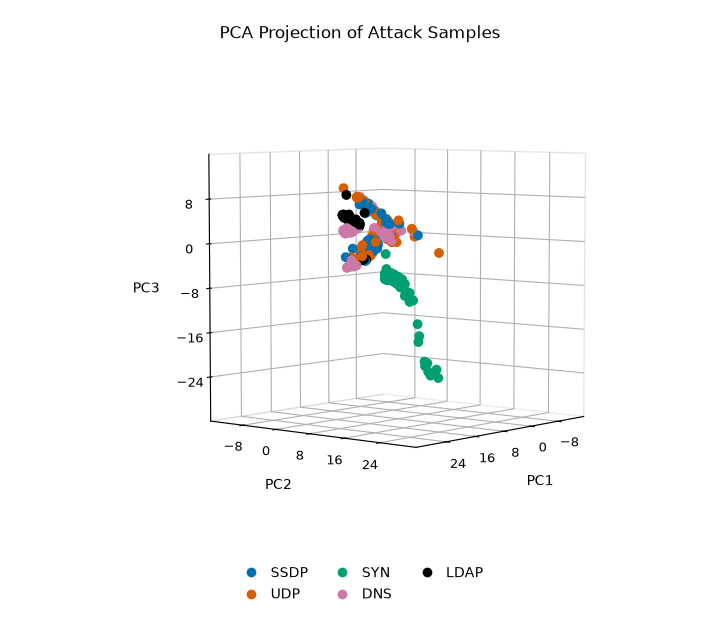

In [4]:
from IPython.display import Image, display

from src.Plots.SimilaritySamples3DPlot import SimilaritySamples3DPlot

plotDatasetPath = "data/similarity/similarity_1s.csv"
plotSelectedFeaturesPath = "output/Similarity/selected_features.csv"
plotOutputPath = "output/Similarity/attack_samples_pca_3d.png"
plotAttacks = ["SSDP", "UDP", "SYN", "DNS", "LDAP"]
samplesPerAttack = 100
sampleRandomSeed = 42
plotPointSize = 50
plotElevation = 5
plotAzimuth = 40
plotDpi = 100
plotTitle = "PCA Projection of Attack Samples"

SimilaritySamples3DPlot().plotFromCsv(
    datasetPath=plotDatasetPath,
    selectedFeaturesPath=plotSelectedFeaturesPath,
    attacks=plotAttacks,
    outputPath=plotOutputPath,
    samplesPerAttack=samplesPerAttack,
    sampleRandomSeed=sampleRandomSeed,
    pointSize=plotPointSize,
    elevation=plotElevation,
    azimuth=plotAzimuth,
    dpi=plotDpi,
    title=plotTitle,
)

display(Image(filename=plotOutputPath))
